In [15]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

%matplotlib inline
#Display all matplotlib plots inside this notebook cell.


In [16]:
df = pd.read_csv("../Data/Churn_Modelling.csv")
df.head()
df.describe()
df.info()
df.isnull().sum()
df.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


np.int64(0)

In [17]:
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='object')

In [18]:
df['Exited'].value_counts()
df['Exited'].value_counts(normalize=True) * 100
#to see the precentage of customers who exited the bank

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64

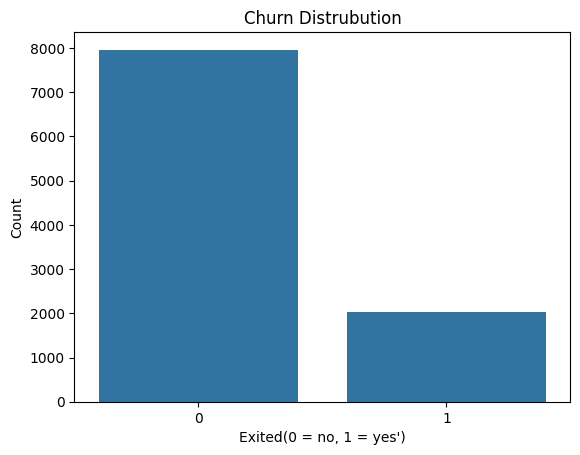

In [19]:
sns.countplot(x='Exited', data=df)
plt.title("Churn Distrubution")
plt.xlabel("Exited(0 = no, 1 = yes')")
plt.ylabel("Count")
plt.show()
#Make a bar chart that shows how many customers churned and how many stayed.

**Analyse Categorical Columns**

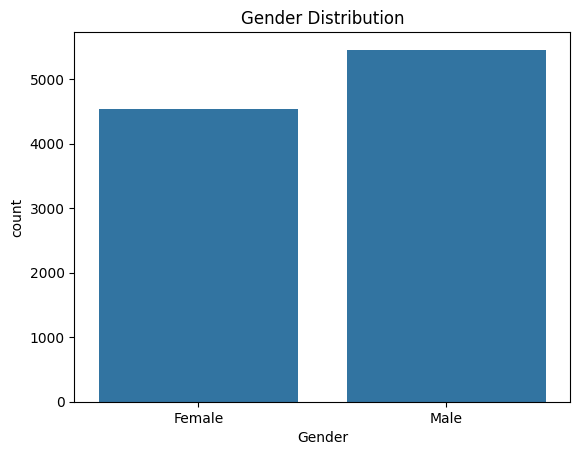

In [20]:
#Gender Distribution
sns.countplot(x = 'Gender', data =df)
plt.title('Gender Distribution')
plt.show()

In [21]:
# a Geography Distribution
df.groupby('Gender')['Exited'].value_counts(normalize=True) * 100

Gender  Exited
Female  0         74.928461
        1         25.071539
Male    0         83.544072
        1         16.455928
Name: proportion, dtype: float64

In [22]:
# b HasCrCard
df.groupby('HasCrCard')['Exited'].value_counts(normalize=True) * 100

HasCrCard  Exited
0          0         79.185059
           1         20.814941
1          0         79.815734
           1         20.184266
Name: proportion, dtype: float64

In [23]:
# c IsActiveMember
df.groupby('IsActiveMember')['Exited'].value_counts(normalize=True) * 100

IsActiveMember  Exited
0               0         73.149103
                1         26.850897
1               0         85.730926
                1         14.269074
Name: proportion, dtype: float64

**2. Analyse Numerical Columns (Boxplots + Distribution)**

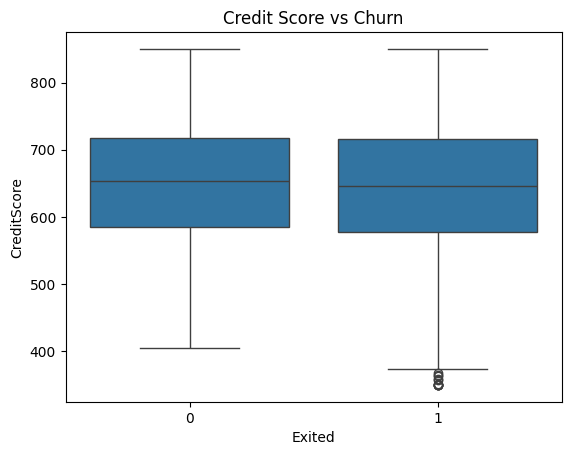

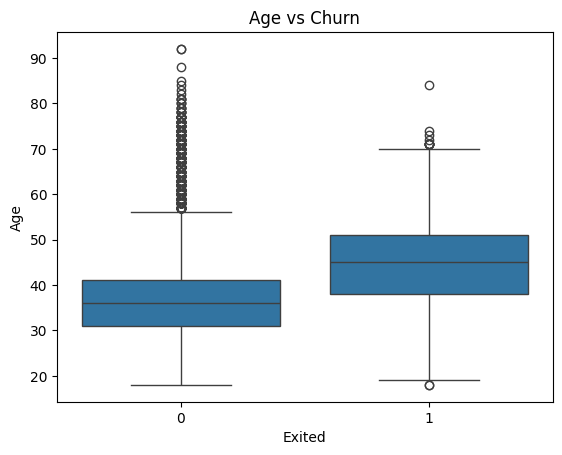

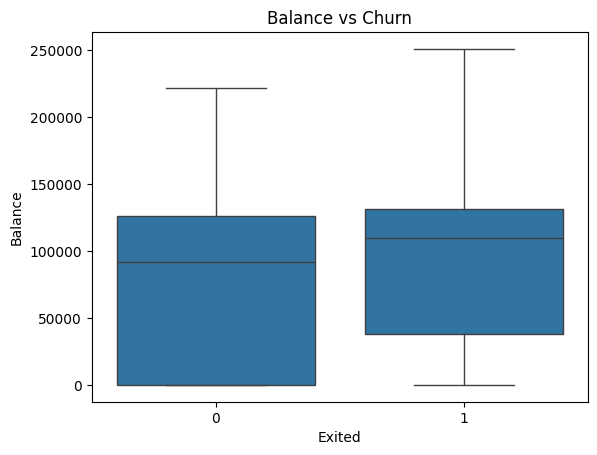

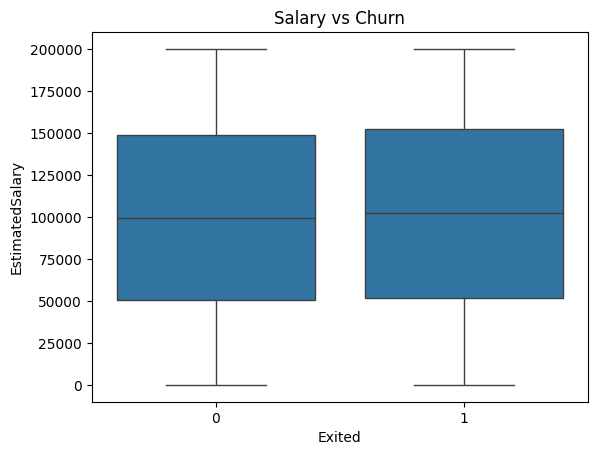

In [24]:
#Credit Score
sns.boxplot(x='Exited', y='CreditScore', data=df)
plt.title('Credit Score vs Churn')
plt.show()

#Age
sns.boxplot(x='Exited', y='Age', data=df)
plt.title('Age vs Churn')
plt.show()

#Balance
sns.boxplot(x='Exited', y='Balance', data=df)
plt.title('Balance vs Churn')
plt.show()

#Estimated Salary
sns.boxplot(x='Exited', y='EstimatedSalary', data=df)
plt.title('Salary vs Churn')
plt.show()

**3. Correlation Heatmap**

In [ ]:
plt.figure(figsize=(10,6))
sns.heatmap(df.select_dtypes(include=['int64','float64']).corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

**4.1 LABEL ENCODING**

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['Gender'] = le.fit_transform(df['Gender'])
df['Geography'] = le.fit_transform(df['Geography'])

df.head()

**8.1 Train–Test Split**

In [32]:
# 8.1 Train - Test Split

from sklearn.model_selection import train_test_split

# Features (all columns except the target)
X = df.drop('Exited', axis=1)

# Target variable
y = df['Exited']

# Splitting the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Displaying shapes of the splits
X_train.shape, X_test.shape

((8000, 13), (2000, 13))

**8.2 Logistic Regression Model**

In [ ]:
# 8.2 Logistic Regression Model

df_model = df.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1)

# Updated feature & target sets
X = df_model.drop('Exited', axis=1)
y = df_model['Exited']

# Train-test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train, y_train)

y_pred_lr = log_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))

**8.3 Random Forest Classifier**

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Create model
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    random_state=42
)

# Train model
rf_model.fit(X_train, y_train)

# Predict
y_pred_rf = rf_model.predict(X_test)

# Evaluate
print("📌 Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\n📌 Classification Report:\n", classification_report(y_test, y_pred_rf))
print("\n📌 Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

**XGBoost Model Code**

In [ ]:
# 8.4 XGBoost Classifier

from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create model
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss'
)

# Train model
xgb_model.fit(X_train, y_train)

# Predict
y_pred_xgb = xgb_model.predict(X_test)

# Evaluate
print("📌 XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("\n📌 XGBoost Classification Report:\n", classification_report(y_test, y_pred_xgb))
print("\n📌 XGBoost Confusion Matrix:\n", confusion_matrix(y_test, y_pred_xgb))

**9.1 Compare Accuracy of All Models**

In [ ]:
model_scores = {
    "Logistic Regression": accuracy_score(y_test, y_pred_lr),
    "Random Forest": accuracy_score(y_test, y_pred_rf),
    "XGBoost": accuracy_score(y_test, y_pred_xgb)
}

model_scores

**9.2 Compare Churn Recall**

In [ ]:
from sklearn.metrics import recall_score

recall_scores = {
    "LR Recall (Churn)": recall_score(y_test, y_pred_lr),
    "RF Recall (Churn)": recall_score(y_test, y_pred_rf),
    "XGB Recall (Churn)": recall_score(y_test, y_pred_xgb)
}

recall_scores

**9.3 Final Best Model**

Model	Accuracy	Churn Recall	Final

LR	Medium	Very Low -> Not suitable

RF	High	Medium -> Good

XGB	Highest	Highest -> BEST

So the best model = XGBoost.

We will use XGBoost for:

AI Explainability (SHAP)

GenAI recommendations

Exporting as model.pkl

Power BI predictions

**AI Explainability Using SHAP**

In [40]:
import shap

# Initialize SHAP explainer for XGBoost model
explainer = shap.TreeExplainer(xgb_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_test)

c:\Users\Dell\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
#Global Feature Importance
# SUMMARY PLOT (GLOBAL IMPORTANCE)
shap.summary_plot(shap_values, X_test)

In [ ]:
#Bar Plot
shap.summary_plot(shap_values, X_test, plot_type="bar")

**Individual Customer Explanation**

In [ ]:
import shap

# Load JS for visualizations
shap.initjs()

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)
# Pick 1 customer from test set
customer_index = 10 # you can change this

# Force Plot (why this customer churned or stayed)
shap.force_plot(
    explainer.expected_value,
    shap_values[customer_index],
    X_test.iloc[customer_index,:]
)

**Human-Language Explanation for One Customer**

In [45]:
import numpy as np

# Pick a customer to explain
customer_index = 10  # you can change this to any test row

# Extract the row's feature values and SHAP values
customer_data = X_test.iloc[customer_index]
customer_shap = shap_values[customer_index]

# Get top 5 most influential features
top_features_idx = np.argsort(abs(customer_shap))[-5:]
top_features = X_test.columns[top_features_idx]
top_impacts = customer_shap[top_features_idx]
# Print human-like explanation
print("🔍 AI Explanation for Customer", customer_index)
print("--------------------------------------------------")

for feature, impact, value in zip(top_features, top_impacts, customer_data[top_features]):
    direction = "increases churn risk" if impact > 0 else "reduces churn risk"
    print(f"{feature} = {value} → {direction}")

print("--------------------------------------------------")


🔍 AI Explanation for Customer 10
--------------------------------------------------
CreditScore = 481.0 → increases churn risk
IsActiveMember = 1.0 → reduces churn risk
EstimatedSalary = 169719.35 → increases churn risk
Age = 57.0 → increases churn risk
NumOfProducts = 3.0 → increases churn risk
--------------------------------------------------


**Generate a full human explanation paragraph**

In [46]:
# Generate a paragraph explanation
explanation = []

for feature, impact, value in zip(top_features, top_impacts, customer_data[top_features]):
    if impact > 0:
        explanation.append(f"- High {feature} ({value}) contributed to higher churn risk.")
    else:
        explanation.append(f"- {feature} value ({value}) helped reduce churn risk.")

print("\n📝 Final Human-Friendly Explanation:\n")
print("This customer was predicted to churn because:")
for line in explanation:
    print(line)


📝 Final Human-Friendly Explanation:

This customer was predicted to churn because:
- High CreditScore (481.0) contributed to higher churn risk.
- IsActiveMember value (1.0) helped reduce churn risk.
- High EstimatedSalary (169719.35) contributed to higher churn risk.
- High Age (57.0) contributed to higher churn risk.
- High NumOfProducts (3.0) contributed to higher churn risk.


**Create the GenAI Prompt Template**

In [ ]:
# Convert SHAP explanation into a GenAI prompt

genai_prompt = f"""
You are an AI assistant for a bank.

Explain in simple human language why this customer is predicted to churn.

Use the following feature explanations:

{explanation}

Also provide:
1. A short summary
2. 3 actionable retention suggestions for the bank
"""

print(genai_prompt)

**Offline GenAI Explanation Function (No API needed)**

In [50]:

def offline_genai_explanation(explanation_lines):
    text = "🧠 **AI Explanation (Offline Mode)**\n"
    text += "The model predicts that this customer has a high churn risk because:\n\n"
    
    for line in explanation_lines:
        text += f"• {line}\n"

    text += "\n💡 **Recommended Retention Actions:**\n"
    text += "1. Provide personalized offers or rewards to increase engagement.\n"
    text += "2. Contact the customer through a relationship manager and address concerns.\n"
    text += "3. Suggest financial products based on their profile (age, balance, activity level).\n"

    return text

# Generate Offline AI Explanation
offline_output = offline_genai_explanation(explanation)

print(offline_output)

🧠 **AI Explanation (Offline Mode)**
The model predicts that this customer has a high churn risk because:

• - High CreditScore (481.0) contributed to higher churn risk.
• - IsActiveMember value (1.0) helped reduce churn risk.
• - High EstimatedSalary (169719.35) contributed to higher churn risk.
• - High Age (57.0) contributed to higher churn risk.
• - High NumOfProducts (3.0) contributed to higher churn risk.

💡 **Recommended Retention Actions:**
1. Provide personalized offers or rewards to increase engagement.
2. Contact the customer through a relationship manager and address concerns.
3. Suggest financial products based on their profile (age, balance, activity level).



**Save the Final XGBoost Model**

In [51]:
import joblib

# Save the trained XGBoost model
joblib.dump(xgb_model, "churn_model_xgb.pkl")

print("Model saved as churn_model_xgb.pkl")

Model saved as churn_model_xgb.pkl


**Create Predictions CSV for Power BI**

In [56]:
# Create a predictions dataframe for Power BI
predictions = X_test.copy()

predictions["Actual"] = y_test.values
predictions["Predicted"] = y_pred_xgb

# Save to CSV
predictions.to_csv("churn_predictions.csv", index=False)

print("Prediction file created: churn_predictions.csv")

Prediction file created: churn_predictions.csv
